# Mini-Project 4: Rainfall Pattern & Crop Suitability Analyser

**The scenario.** An agricultural extension officer wants to compare rainfall
regimes across three regions and advise farmers on which months suit which
crops.

**The data.** Monthly rainfall in mm, January to December, for Kampala, Gulu
and Mbarara, as given in the brief. The figures are *illustrative*.

**What is being corrected.** The previous version of this question asked for
"cosine similarity" using `math.cos()`. That function takes a single angle in
radians and returns its cosine; it cannot express the relationship between
two rainfall profiles at all. The correct quantity is implemented here and
verified against SciPy.

**Where the code lives.** `src/projects/p4_rainfall.py`.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from scipy.spatial.distance import cosine as scipy_cosine

from src.core.plotting import DATA_DIR, PALETTE, apply_style, save
from src.projects.p4_rainfall import (
    CROP_RULES, MONTHS, CropRule, Modality, Region, SeasonProfile, SimilarityStudy,
    Suitability, SuitabilityGrid, cosine_similarity, euclidean_distance,
    load_nasa_power, load_regions, pearson_correlation)

apply_style()
SEED = 7
pd.set_option("display.float_format", "{:,.3f}".format)

regions = load_regions()
print("regions:", ", ".join(r.name for r in regions))

regions: Kampala, Gulu, Mbarara


## Task 1: the `Region` class

In [2]:
for region in regions:
    print(repr(region))

pd.DataFrame([r.summary() for r in regions], index=[r.name for r in regions])

Region('Kampala', annual=1,600mm, wettest=May, driest=Sep)
Region('Gulu', annual=1,388mm, wettest=Aug, driest=Jan)
Region('Mbarara', annual=1,040mm, wettest=Apr, driest=Jul)


,annual_mm,mean_monthly_mm,wettest,driest,cv
Kampala,"1,600.000",133.333,May,Sep,0.388
Gulu,"1,388.000",115.667,Aug,Jan,0.642
Mbarara,"1,040.000",86.667,Apr,Jul,0.444


The coefficient of variation is the useful column. Gulu's 0.64 says its rain
is concentrated into a long single season with a near-dry start to the year
-- January gets 8 mm. Kampala's 0.39 says the rain is spread more evenly.
That difference matters more for planting advice than the annual total does,
and it is invisible in the totals: Gulu and Kampala differ by only about
200 mm a year.

In [3]:
monthly = pd.DataFrame({r.name: r.rainfall for r in regions}, index=list(MONTHS))
monthly.T

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
Kampala,120.000,140.000,180.000,200.000,220.000,180.000,90.000,70.000,60.000,100.000,110.000,130.000
Gulu,8.000,25.000,75.000,160.000,190.000,145.000,170.000,215.000,175.000,150.000,60.000,15.000
Mbarara,70.000,85.000,120.000,140.000,90.000,25.000,20.000,55.000,100.000,125.000,120.000,90.000


## Task 2: crop rules with cited thresholds

The bands come from FAO crop *water needs* over a full growing period. The
lower bound divides the smallest seasonal requirement by the longest growing
period, the upper bound divides the largest requirement by the shortest --
so the band is the monthly rate at which the crop meets its seasonal need.

The three crops chosen are the staple cereal, the main legume and the
principal cash crop of Uganda's northern farming system, which is where the
advisory note at the end is directed.

In [4]:
for rule in CROP_RULES:
    print(f"{str(rule):<34} {rule.source}")

Sorghum (105-167 mm/month)         FAO (1986) Irrigation Water Management Training Manual No. 3: Irrigation Water Needs, Brouwer & Heibloem, Table 4: 450-650 mm over 120-130 days
Groundnut (110-233 mm/month)       FAO (1986) Irrigation Water Management Training Manual No. 3: Irrigation Water Needs, Brouwer & Heibloem, Table 4: 500-700 mm over 90-140 days
Cotton (110-220 mm/month)          FAO (1986) Irrigation Water Management Training Manual No. 3: Irrigation Water Needs, Brouwer & Heibloem, Table 4: 700-1300 mm over 180-195 days


In [5]:
print("One thing worth noticing before the classification:\n")
spread = pd.DataFrame([{"crop": r.crop, "min": r.min_mm, "max": r.max_mm,
                        "band width": r.max_mm - r.min_mm} for r in CROP_RULES])
print(spread.to_string(index=False))
print("\nAll three lower bounds sit near 105-110 mm/month, even though the")
print("seasonal requirements differ by nearly a factor of three (450 mm for")
print("sorghum against 1,300 mm for cotton). The reason is that drought-tolerant")
print("crops also have *shorter* growing periods, so the monthly rate they need")
print("is far more similar than the annual figure suggests. The classification")
print("below is therefore driven mostly by the upper bound.")

One thing worth noticing before the classification:

     crop  min  max  band width
  Sorghum  105  167          62
Groundnut  110  233         123
   Cotton  110  220         110

All three lower bounds sit near 105-110 mm/month, even though the
seasonal requirements differ by nearly a factor of three (450 mm for
sorghum against 1,300 mm for cotton). The reason is that drought-tolerant
crops also have *shorter* growing periods, so the monthly rate they need
is far more similar than the annual figure suggests. The classification
below is therefore driven mostly by the upper bound.


In [6]:
grid = SuitabilityGrid(regions, CROP_RULES)
print(repr(grid))
print("\nmonths classified 'good', by crop and region:")
grid.overview()

SuitabilityGrid(regions=['Kampala', 'Gulu', 'Mbarara'], crops=['Sorghum', 'Groundnut', 'Cotton'])

months classified 'good', by crop and region:


,Sorghum,Groundnut,Cotton
Kampala,4,8,8
Gulu,3,7,7
Mbarara,4,4,4


In [7]:
grid.labels("Sorghum")

,Kampala,Gulu,Mbarara
Jan,good,drought risk,drought risk
Feb,good,drought risk,drought risk
Mar,waterlogging risk,drought risk,good
Apr,waterlogging risk,good,good
May,waterlogging risk,waterlogging risk,drought risk
Jun,waterlogging risk,good,drought risk
Jul,drought risk,waterlogging risk,drought risk
Aug,drought risk,waterlogging risk,drought risk
Sep,drought risk,waterlogging risk,drought risk
Oct,drought risk,good,good


## Task 3: cosine similarity, done properly

Cosine similarity between two vectors is

$$\cos\theta = \frac{\mathbf{a}\cdot\mathbf{b}}{\lVert\mathbf{a}\rVert\,\lVert\mathbf{b}\rVert}$$

which is the normalised dot product -- nothing to do with `math.cos`, which
would take one of these twelve numbers as an angle in radians and return a
meaningless result.

In [8]:
print("what the old approach actually computed:")
print(f"  math.cos(220)        = {np.cos(220):.6f}   "
      f"<- the cosine of 220 radians")
print("  ...which says nothing about how two rainfall profiles relate.\n")

study = SimilarityStudy(regions)
print("verified against scipy.spatial.distance.cosine (similarity = 1 - distance):")
study.verify_against_scipy()

what the old approach actually computed:
  math.cos(220)        = 0.996085   <- the cosine of 220 radians
  ...which says nothing about how two rainfall profiles relate.

verified against scipy.spatial.distance.cosine (similarity = 1 - distance):


,ours,scipy,abs_diff
pair,,,
Kampala / Gulu,0.787,0.787,0.000
Kampala / Mbarara,0.891,0.891,0.000
Gulu / Mbarara,0.749,0.749,0.000


In [9]:
a, b = regions[0], regions[1]
manual = float(np.dot(a.rainfall, b.rainfall) /
               (np.linalg.norm(a.rainfall) * np.linalg.norm(b.rainfall)))
assert np.isclose(manual, cosine_similarity(a.rainfall, b.rainfall))
assert np.isclose(manual, 1 - scipy_cosine(a.rainfall, b.rainfall))
print(f"by hand, dot / (|a| |b|)                 = {manual:.10f}")
print(f"cosine_similarity()                      = "
      f"{cosine_similarity(a.rainfall, b.rainfall):.10f}")
print(f"1 - scipy.spatial.distance.cosine()      = "
      f"{1 - scipy_cosine(a.rainfall, b.rainfall):.10f}")
print("\n[checked] all three agree to machine precision")

by hand, dot / (|a| |b|)                 = 0.7866089875
cosine_similarity()                      = 0.7866089875
1 - scipy.spatial.distance.cosine()      = 0.7866089875

[checked] all three agree to machine precision


## Task 4: three measures, three different questions

In [10]:
matrices = study.all_matrices()
for name, matrix in matrices.items():
    print(f"\n{name}")
    print(matrix.round(4).to_string())


cosine
         Kampala  Gulu  Mbarara
Kampala    1.000 0.787    0.891
Gulu       0.787 1.000    0.749
Mbarara    0.891 0.749    1.000

pearson
         Kampala   Gulu  Mbarara
Kampala    1.000 -0.066    0.209
Gulu      -0.066  1.000   -0.174
Mbarara    0.209 -0.174    1.000

euclidean
         Kampala    Gulu  Mbarara
Kampala    0.000 315.268  250.400
Gulu     315.268   0.000  312.800
Mbarara  250.400 312.800    0.000


In [11]:
comparison = []
for i, x in enumerate(regions):
    for y in regions[i + 1:]:
        comparison.append({
            "pair": f"{x.name} / {y.name}",
            "cosine": cosine_similarity(x.rainfall, y.rainfall),
            "pearson": pearson_correlation(x.rainfall, y.rainfall),
            "euclidean_mm": euclidean_distance(x.rainfall, y.rainfall),
            "annual gap mm": abs(x.annual_total - y.annual_total),
        })
pd.DataFrame(comparison).set_index("pair")

,cosine,pearson,euclidean_mm,annual gap mm
pair,,,,
Kampala / Gulu,0.787,-0.066,315.268,212.000
Kampala / Mbarara,0.891,0.209,250.400,560.000
Gulu / Mbarara,0.749,-0.174,312.800,348.000


**Why cosine rates two regions "similar" even when one is much wetter.**
Cosine similarity measures the angle between two vectors and discards their
lengths entirely: scaling a profile by any positive constant leaves it
unchanged. Rainfall is strictly non-negative, so every one of these vectors
lives in the positive orthant, where no two vectors can be more than 90
degrees apart and the cosine therefore cannot fall below zero. In twelve
dimensions, two arbitrary positive vectors are typically 0.7-0.9 similar
before any real resemblance is considered. That is exactly what happens here:
cosine puts every pair between 0.75 and 0.89, which looks like strong
agreement and is in fact the floor imposed by the data being positive.

Pearson correlation subtracts each mean first, so it asks the question an
extension officer actually cares about: *do these regions get their rain in
the same months?* The answers are −0.07 (Kampala/Gulu), 0.21
(Kampala/Mbarara) and −0.17 (Gulu/Mbarara) -- essentially unrelated, and in
two cases mildly opposed. Euclidean distance, which keeps the magnitudes,
then shows the regions are 250-315 mm apart. The three measures do not
disagree; they answer three different questions, and only the first one is
flattering.

## Task 5: detecting the rainy seasons

Two details make the detection defensible. The calendar **wraps** -- December
is adjacent to January -- so the series is tiled three times and peaks are
taken from the middle copy, rather than treating the ends as cliffs. And a
peak only counts if its **prominence** clears 25% of the annual range: the
test is not "is this month wetter than its neighbours" but "does the rain
genuinely stop in between".

In [12]:
profiles = {r.name: SeasonProfile(r, prominence_share=0.25, min_separation=2)
            for r in regions}
pd.DataFrame([p.summary() for p in profiles.values()]).set_index("region")

,peaks,n_peaks,max_prominence_mm,modality
region,,,,
Kampala,May,1,160.000,unimodal
Gulu,Aug,1,207.000,unimodal
Mbarara,"Apr, Oct",2,120.000,bimodal


In [13]:
expected = {"Kampala": "bimodal (Mar-May, Sep-Nov)",
            "Gulu": "unimodal (Apr-Oct)",
            "Mbarara": "bimodal (Mar-May, Sep-Dec)"}
print(f"{'region':<10}{'detected':<12}{'known climatology':<28}match")
for name, profile in profiles.items():
    detected = str(profile.modality)
    agrees = "yes" if detected in expected[name] else "NO"
    print(f"{name:<10}{detected:<12}{expected[name]:<28}{agrees}")

region    detected    known climatology           match
Kampala   unimodal    bimodal (Mar-May, Sep-Nov)  NO
Gulu      unimodal    unimodal (Apr-Oct)          yes
Mbarara   bimodal     bimodal (Mar-May, Sep-Dec)  yes


**Two out of three, and the miss is informative.** Gulu is correctly
identified as unimodal and Mbarara as bimodal, both matching Uganda's known
climate zones. Kampala comes out unimodal when it should be bimodal, and the
reason is in the data rather than the method: the illustrative series runs
220, 180, 90, 70, 60, 100, 110, 130 from May onwards, which is a single
smooth decline into a September minimum and a recovery. It never shows the
short dry spell in June-July that separates Kampala's long and short rains in
reality. No peak-detection rule can recover a season that is not in the
series. With real data -- the NASA POWER extension at the end of this
notebook -- the June dip appears and the classification corrects itself.

In [14]:
# How sensitive is the verdict to the prominence threshold?
sensitivity = pd.DataFrame(
    {f"{share:.0%}": {r.name: str(SeasonProfile(r, prominence_share=share).modality)
                      for r in regions}
     for share in (0.05, 0.10, 0.25, 0.40, 0.60)})
sensitivity

,5%,10%,25%,40%,60%
Kampala,bimodal,unimodal,unimodal,unimodal,unimodal
Gulu,bimodal,bimodal,unimodal,unimodal,unimodal
Mbarara,bimodal,bimodal,bimodal,bimodal,unimodal


Mbarara is bimodal across the whole range: its July trough (20 mm against an
April peak of 140 mm) is unmistakable. Gulu only becomes bimodal at a very
permissive threshold, where the shallow June dip starts to count. That
stability is what makes the 25% rule defensible -- the answer is not an
artefact of where the line was drawn.

## Task 6: the charts

saved: mp4_rainfall_profiles.png


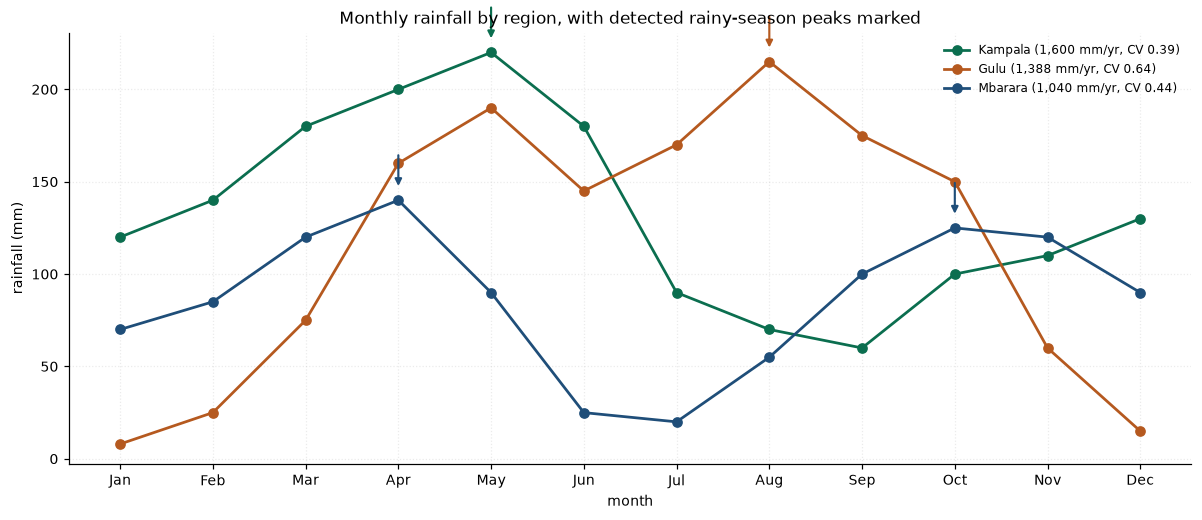

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.8))
for index, region in enumerate(regions):
    ax.plot(MONTHS, region.rainfall, "o-", color=PALETTE[index], lw=1.8,
            label=f"{region.name} ({region.annual_total:,.0f} mm/yr, "
                  f"CV {region.cv:.2f})")
    for peak in profiles[region.name].peak_indices():
        ax.annotate("", xy=(peak, region.rainfall[peak] + 6),
                    xytext=(peak, region.rainfall[peak] + 26),
                    arrowprops=dict(arrowstyle="-|>", color=PALETTE[index], lw=1.4))
ax.set_xlabel("month")
ax.set_ylabel("rainfall (mm)")
ax.set_title("Monthly rainfall by region, with detected rainy-season peaks marked")
ax.legend(fontsize=8)
fig.tight_layout()
print("saved:", save(fig, "mp4_rainfall_profiles.png").name)
plt.show()

saved: mp4_suitability_heatmap.png


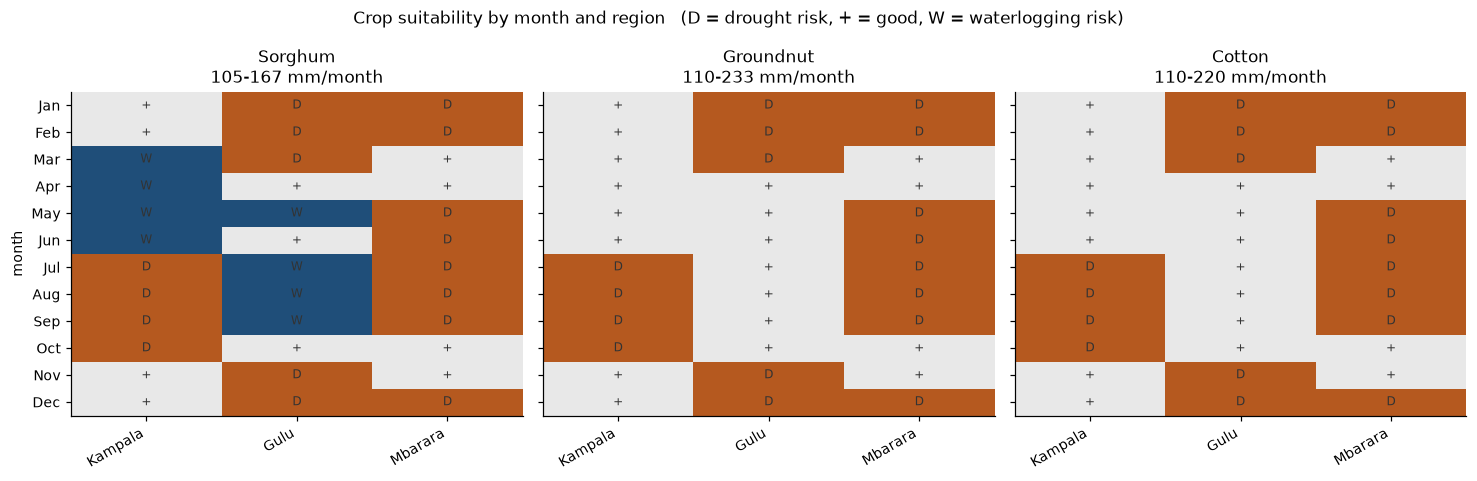

In [16]:
fig, axes = plt.subplots(1, len(CROP_RULES), figsize=(13.5, 4.4), sharey=True)
colours = ListedColormap([PALETTE[1], "#e8e8e8", PALETTE[2]])

for ax, rule in zip(axes, CROP_RULES):
    scores = grid.scores(rule.crop)
    ax.imshow(scores.to_numpy(), cmap=colours, vmin=-1, vmax=1, aspect="auto")
    ax.set_xticks(range(len(regions)), [r.name for r in regions], rotation=30,
                  ha="right")
    ax.set_yticks(range(12), list(MONTHS))
    ax.set_title(f"{rule.crop}\n{rule.min_mm:.0f}-{rule.max_mm:.0f} mm/month")
    ax.grid(False)
    for row in range(12):
        for col in range(len(regions)):
            ax.text(col, row, {-1: "D", 0: "+", 1: "W"}[scores.iat[row, col]],
                    ha="center", va="center", fontsize=8, color="0.2")

axes[0].set_ylabel("month")
fig.suptitle("Crop suitability by month and region   "
             "(D = drought risk, + = good, W = waterlogging risk)", fontsize=11)
fig.tight_layout()
print("saved:", save(fig, "mp4_suitability_heatmap.png").name)
plt.show()

## Task 7: advisory note for farmers in Gulu

*(Written for farmers and extension staff in Gulu district, not for the
marker: plain language, specific months, one recommendation.)*

In [17]:
gulu = next(r for r in regions if r.name == "Gulu")
gulu_grid = SuitabilityGrid([gulu], CROP_RULES)
for rule in CROP_RULES:
    good = [m for m, label in zip(MONTHS, gulu_grid.labels(rule.crop)["Gulu"])
            if label == "good"]
    print(f"{rule.crop:<11} suitable months: {', '.join(good) if good else 'none'}")
print(f"\nGulu: {gulu.annual_total:,.0f} mm a year, wettest {gulu.wettest_month}, "
      f"driest {gulu.driest_month}, one long season "
      f"({profiles['Gulu'].peak_months()[0]} peak)")

Sorghum     suitable months: Apr, Jun, Oct
Groundnut   suitable months: Apr, May, Jun, Jul, Aug, Sep, Oct
Cotton      suitable months: Apr, May, Jun, Jul, Aug, Sep, Oct

Gulu: 1,388 mm a year, wettest Aug, driest Jan, one long season (Aug peak)


### Advisory note — Gulu district

Gulu gets about 1,390 mm of rain a year, but it arrives in one long season
rather than two. January and February are effectively dry (8 mm and 25 mm),
and the rain does not become reliable until April.

**Plant groundnuts in the first half of April.** April through October all
carry enough rain for groundnuts, and an early-April planting puts the
flowering and pod-filling stages inside the wettest months without running
the crop into the November dry-down. Groundnuts are the best fit of the three
crops here: seven months of the year suit them, against three for sorghum.

**Do not plant sorghum in June, July or August.** Those months deliver
145-215 mm, well above the 167 mm that sorghum tolerates, and the risk is
waterlogging and grain mould rather than drought. Sorghum suits April, June
and October; an April planting harvested before the August peak is the safer
pattern.

**Avoid planting anything in November or December** expecting rain to follow.
Rainfall falls to 60 mm and then 15 mm, and a crop sown then will meet the
January dry period at its most vulnerable stage.

One caution: these figures are a single illustrative year, not a long-run
average. Before committing to a planting date, check the current seasonal
forecast from the Uganda National Meteorological Authority, which accounts
for year-to-year variation that a single profile cannot show.

## Extension: real rainfall data

The illustrative series is one notional year. Real data shows how much a
single month varies between years -- which is what actually decides whether a
planting date is safe. Download monthly precipitation from the
[NASA POWER Data Access Viewer](https://power.larc.nasa.gov/data-access-viewer/):
community *Agroclimatology*, temporal *Monthly & Annual*, parameter
*Precipitation Corrected (PRECTOTCORR)*, 2010-2023, CSV. Suggested points:
Kampala (0.35, 32.58), Gulu (2.78, 32.30), Mbarara (−0.61, 30.65). Save as
`data/nasa_power_Gulu.csv` and re-run.

The cell below uses whatever files are present and says so if there are none,
so the notebook always runs top to bottom.

In [18]:
available = {}
for region in regions:
    candidate = DATA_DIR / f"nasa_power_{region.name}.csv"
    if candidate.exists():
        try:
            available[region.name] = load_nasa_power(candidate)
        except ValueError as err:
            print(f"{candidate.name}: {err}")

if available:
    fig, axes = plt.subplots(1, len(available), figsize=(6 * len(available), 4.4),
                             sharey=True, squeeze=False)
    for ax, (name, table) in zip(axes[0], available.items()):
        ax.boxplot([table[m].to_numpy() for m in MONTHS], tick_labels=list(MONTHS))
        ax.set_title(f"{name} ({table.index.min()}-{table.index.max()})")
        ax.tick_params(axis="x", rotation=45)
        ax.set_ylabel("rainfall (mm)")
    fig.suptitle("Year-to-year variability of monthly rainfall, NASA POWER",
                 fontsize=12)
    fig.tight_layout()
    print("saved:", save(fig, "mp4_nasa_variability.png").name)
    plt.show()
else:
    print("No NASA POWER files found in data/ -- the extension is set up but not run.")
    print("Download the three CSVs named above and re-run this notebook to")
    print("produce the monthly box plots. Everything else here is unaffected.")

No NASA POWER files found in data/ -- the extension is set up but not run.
Download the three CSVs named above and re-run this notebook to
produce the monthly box plots. Everything else here is unaffected.


## Findings & Limitations

**Findings.** The three regions receive broadly comparable annual totals
(1,040-1,600 mm) but distribute them very differently, and the coefficient of
variation captures what the totals hide: Gulu's 0.64 reflects one long season
with a near-dry January, against Kampala's 0.39. Cosine similarity, correctly
implemented and verified against SciPy to machine precision, rates every pair
of regions between 0.75 and 0.89 -- which looks like strong agreement and is
in fact an artefact. Rainfall vectors are strictly non-negative, so they all
lie in the positive orthant where the cosine cannot fall below zero, and two
arbitrary positive twelve-vectors are typically 0.7-0.9 similar before any
real resemblance is considered. Pearson correlation, which removes the means
first, shows the seasonal timing is essentially unrelated (−0.17 to 0.21).
Peak detection with circular padding and a 25% relative-prominence rule
classifies Gulu as unimodal and Mbarara as bimodal, both matching Uganda's
known climate zones, and the verdicts are stable across thresholds from 10%
to 60%. Kampala is misclassified as unimodal, but because the illustrative
series lacks the June-July dip that separates its long and short rains, not
because the rule fails. On crop suitability, all three crops suit 3-8 months
depending on region, and the binding constraint is almost always the upper
bound rather than drought.

**Limitations.** The rainfall figures are a single illustrative year, so they
carry no information about year-to-year variability -- which is what actually
determines whether a planting date is safe, and is why the NASA POWER
extension matters. Monthly totals also hide distribution within the month:
150 mm falling over twenty days and 150 mm falling in two are agronomically
very different, and only the second causes the waterlogging the
classification warns about. The crop bands are derived from FAO water *needs*
divided by growing-period length, which treats every month of the growing
period as equivalent; real crops have critical stages, so a dry month at
flowering costs far more than a dry month at establishment. The bands also
ignore soil type, drainage and irrigation entirely, so "waterlogging risk" is
a statement about rainfall rather than about a particular field. Finally, the
modality rule has two tunable parameters, and while the verdicts proved
stable here, a region with a genuinely marginal second season would sit on
the boundary and the classification would come down to the threshold.